# LOGISTIC REGRESSION - C LEMAH (C=100)

### Deskripsi Teori & Varian:
* **Algoritma**: Logistic Regression (L2)
* **Varian**: Penalti Sangat Longgar (C = 100)
* **Konsep**: Nilai C yang sangat besar (100) berarti penalti sangat longgar. Model diberikan kebebasan penuh untuk mencari bobot optimal tanpa banyak hukuman. Varian ini diuji untuk melihat apakah dengan membiarkan model belajar lebih bebas, akurasi bisa meningkat, atau justru memicu *overfitting* (menghafal data latih namun gagal di data uji).

In [1]:
import time
import tracemalloc
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

df_hoaks = pd.read_csv('../data/komdigi_hoaks.csv')
df_valid = pd.read_csv('../web/uploads/berita_valid_terbaru.csv')

def clean_text(text):
    if not isinstance(text, str): return ''
    text = re.sub(r'\[(HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\((HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\)', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

df_hoaks['teks_bersih'] = (df_hoaks['title'].fillna('') + ' ' + df_hoaks['excerpt'].fillna('')).apply(clean_text)
df_valid['teks_bersih'] = (df_valid['title'].fillna('') + ' ' + df_valid['excerpt'].fillna('')).apply(clean_text)

df_hoaks['label'] = 1
df_valid['label'] = 0

df_hoaks_sampel = df_hoaks.sample(n=len(df_valid), random_state=42)
df_all = pd.concat([df_hoaks_sampel, df_valid], ignore_index=True)
df_all = df_all[df_all['teks_bersih'].str.len() > 10].reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    df_all['teks_bersih'], df_all['label'], test_size=0.2, random_state=42, stratify=df_all['label']
)
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print("Preprocessing Selesai!")

Preprocessing Selesai!


In [2]:
tracemalloc.start()
waktu_mulai = time.time()

# Model Logistic Regression L2 dengan C Sangat Lemah (100)
model = LogisticRegression(penalty='l2', solver='lbfgs', C=100.0, max_iter=2000, random_state=42)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

waktu_eksekusi = time.time() - waktu_mulai
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
memori_mb = peak_mem / (1024 * 1024)

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=============================================")
print("HASIL PENGUJIAN: LOGISTIC REGRESSION - C LEMAH (100)")
print("=============================================")
print(f"1. Algoritma        : Logistic Regression")
print(f"2. Metrik Jarak     : L2 Regularization (C=100)")
print(f"3. Akurasi          : {acc:.4f}")
print(f"4. Precision (Macro): {prec_macro:.4f}")
print(f"5. Recall (Macro)   : {rec_macro:.4f}")
print(f"6. F1-Score (Macro) : {f1_macro:.4f}")
print(f"7. F1-Score (Weighted): {f1_weighted:.4f}")
print(f"8. Waktu Eksekusi   : {waktu_eksekusi:.4f} detik")
print(f"9. Penggunaan Memori: {memori_mb:.2f} MB")
print("=============================================\n")

print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['Valid (0)', 'Hoaks (1)'], zero_division=0))

HASIL PENGUJIAN: LOGISTIC REGRESSION - C LEMAH (100)
1. Algoritma        : Logistic Regression
2. Metrik Jarak     : L2 Regularization (C=100)
3. Akurasi          : 0.8933
4. Precision (Macro): 0.8934
5. Recall (Macro)   : 0.8933
6. F1-Score (Macro) : 0.8933
7. F1-Score (Weighted): 0.8933
8. Waktu Eksekusi   : 0.0314 detik
9. Penggunaan Memori: 0.60 MB

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

   Valid (0)       0.90      0.89      0.89       150
   Hoaks (1)       0.89      0.90      0.89       150

    accuracy                           0.89       300
   macro avg       0.89      0.89      0.89       300
weighted avg       0.89      0.89      0.89       300



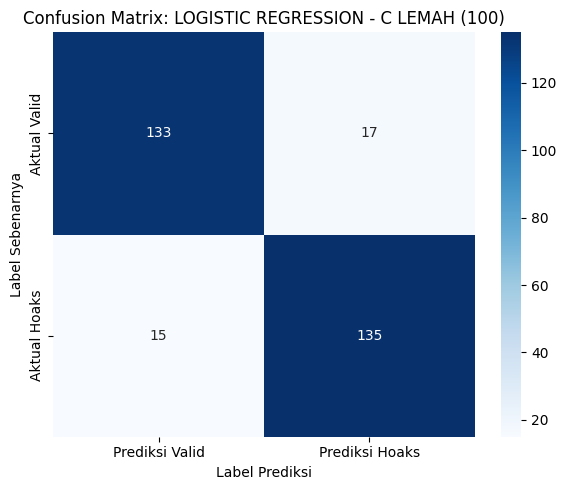

In [3]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Valid', 'Prediksi Hoaks'],
            yticklabels=['Aktual Valid', 'Aktual Hoaks'])
plt.title('Confusion Matrix: LOGISTIC REGRESSION - C LEMAH (100)')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.show()

### Pembahasan Akademis: Logistic Regression (L2 dengan C Lemah = 100)

1. **Analisis Performa & Akurasi**:
   * Model dengan penalti sangat longgar (C=100) menghasilkan akurasi sebesar **89.33%** dengan F1-Score 0.8933. 
   * Menariknya, akurasi ini sama persis dengan C Kuat (0.01), namun *Confusion Matrix*-nya menunjukkan perilaku yang berbeda. Model ini jauh lebih seimbang: berhasil menebak 133 Valid dan 135 Hoaks dengan benar. 
   * Artinya, dengan melonggarkan penalti, model menjadi lebih berani dalam memberikan bobot tinggi pada kata-kata kunci (seperti "viralkan", "awas"), sehingga lebih sensitif dalam mendeteksi Hoaks (hanya 15 yang lolos).

2. **Efek Penalti Lemah (Risiko Overfitting)**:
   * Parameter `C=100` membuat model hampir tidak memiliki hukuman terhadap besarnya bobot. Secara teori, ini sangat berisiko memicu *overfitting* (model menghafal data latih dan gagal saat diuji).
   * Namun, fakta bahwa akurasinya tetap stabil di **89.33%** membuktikan bahwa data teks TF-IDF (yang sudah sangat jarang/sparse) membuat model Logistic Regression tidak mudah terjebak *overfitting*, meskipun kita melonggarkan penaltinya secara ekstrem.

3. **Trade-off dengan Waktu Komputasi**:
   * Waktu eksekusinya 0.0314 detik, sedikit lebih lambat dibanding C Kuat (0.0149 detik). Hal ini wajar karena model harus melakukan iterasi lebih banyak untuk mencari bobot yang lebih bebas tanpa penalti ketat.